# 04 - Physical Units and Quantities

This notebook demonstrates SI-based unit validation and conversion through `quantum_space_agi.scientific.units`.

A quantity is a finite numerical value associated with a unit. A unit stores:

- a display symbol,
- a scale to SI base units, and
- seven integer SI dimension exponents ordered as

$$(L,M,T,I,\Theta,N,J).$$

Conversion uses
$$v_{target}=v_{source}\frac{s_{source}}{s_{target}}.$$

Conversions are permitted only when dimension vectors match.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
repo_root = next((p for p in (cwd, *cwd.parents) if (p / "src").is_dir()), cwd)
sys.path.insert(0, str(repo_root / "src"))

import matplotlib.pyplot as plt
from quantum_space_agi.scientific import units
from quantum_space_agi.scientific.errors import ScientificError


## Unit lookup and conversion

Registered units include meters, kilometers, seconds, hours, kilograms, grams, velocity, acceleration, force, and energy.

In [2]:
distance = units.Quantity(5, units.get_unit("km"))
distance_m = units.convert(distance, "m")

speed = units.Quantity(36, units.get_unit("km/h"))
speed_si = units.convert(speed, "m/s")

duration = units.Quantity(2, units.get_unit("h"))
duration_si = units.convert(duration, "s")

print(distance_m)
print(speed_si)
print(duration_si)


Quantity(value=5000.0, unit=Unit(symbol='m', scale_to_si=1.0, dimensions=(1, 0, 0, 0, 0, 0, 0)))
Quantity(value=10.0, unit=Unit(symbol='m/s', scale_to_si=1.0, dimensions=(1, 0, -1, 0, 0, 0, 0)))
Quantity(value=7200.0, unit=Unit(symbol='s', scale_to_si=1.0, dimensions=(0, 0, 1, 0, 0, 0, 0)))


**Expected results:**

- `5 km = 5000 m`
- `36 km/h = 10 m/s`
- `2 h = 7200 s`


In [3]:
assert units.convert(units.Quantity(5, units.get_unit("km")), "m").value == 5000.0
assert abs(units.convert(units.Quantity(36, units.get_unit("km/h")), "m/s").value - 10.0) < 1e-12
assert units.convert(units.Quantity(2, units.get_unit("h")), "s").value == 7200.0
print("Unit conversion validations passed.")


Unit conversion validations passed.


## Compatibility and failure cases

Compatible dimensions can be converted. Incompatible dimensions and unknown units raise structured errors.

In [4]:
print("km and m compatible:", units.is_compatible("km", "m"))
print("km and s compatible:", units.is_compatible("km", "s"))

try:
    units.convert(units.Quantity(5, units.get_unit("km")), "s")
except ScientificError as exc:
    print("expected conversion error:", exc.code.value)


km and m compatible: True
km and s compatible: False
expected conversion error: unit_mismatch


**Expected:** kilometers and meters are compatible; kilometers and seconds are not; an incompatible conversion raises `unit_mismatch`.

## Visualization: speed conversion curve

The same physical speed appears as different numeric values under `km/h` and `m/s`.

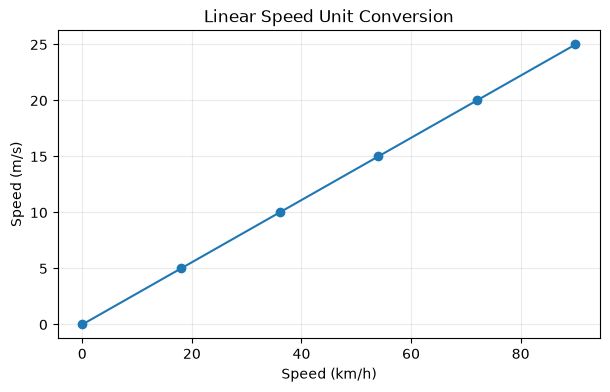

[(0, 0.0), (18, 5.0), (36, 10.0), (54, 15.0), (72, 20.0), (90, 25.0)]


In [5]:
km_per_hour = [0, 18, 36, 54, 72, 90]
meters_per_second = [
    units.convert(units.Quantity(v, units.get_unit("km/h")), "m/s").value
    for v in km_per_hour
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(km_per_hour, meters_per_second, marker="o")
ax.set_xlabel("Speed (km/h)")
ax.set_ylabel("Speed (m/s)")
ax.set_title("Linear Speed Unit Conversion")
ax.grid(True, alpha=0.25)
plt.show()

print(list(zip(km_per_hour, meters_per_second)))


**Expected points:** `(0,0)`, `(18,5)`, `(36,10)`, `(54,15)`, `(72,20)`, `(90,25)`.

## Custom units

A custom unit may be constructed when needed, provided its symbol, positive finite scale, and seven integer dimensions are valid.

In [6]:
millimeter = units.Unit("mm", 0.001, (1, 0, 0, 0, 0, 0, 0))
converted = units.convert(units.Quantity(1000, millimeter), "m")
print(converted)
assert converted.value == 1.0
assert converted.unit.symbol == "m"


Quantity(value=1.0, unit=Unit(symbol='m', scale_to_si=1.0, dimensions=(1, 0, 0, 0, 0, 0, 0)))


## Numerical and modeling limitations

- Unit conversion is linear and scale-based; offsets such as temperature conversion require a separate quantity model.
- The current registry does not include astronomical units, light-years, Celsius, radians, or derived aerospace conventions.
- Values and scales are Float64 concepts and can round at conversion boundaries.
- Unit metadata is checked only for dimensional compatibility; coordinate frames and uncertainty are not modeled.
- `Quantity` and `Unit` are immutable, but that immutability does not replace dimensional analysis by the caller.